# Capstone Black-Box Optimization (BBO): Method, Code & Final Week 13 Results

**Author:** Nicolas Matheou  
**Repository:** [nmatheou/capstone-bbo](https://github.com/nmatheou/capstone-bbo)  
**Supporting Governance Docs:** [Datasheet](docs/datasheet.md) | [Model Card](docs/model_card.md) | [Architecture](docs/architecture.md) | [Reproducibility](docs/reproducibility.md) | [Week 13 Final Analysis](docs/week_13_analysis.md)

---

## 1. Non-Technical Summary (General Audience)

Many real-world challenges—such as discovering effective drug formulations, tuning machine-learning systems, or maximising industrial chemical yields—require finding the best settings for a system whose internal formula is hidden and where every test is slow or expensive. In this 13-week project, I optimised eight unknown "black-box" functions ranging from two to eight input variables, allowed only one test per function each week. I built a hybrid decision engine combining probabilistic Gaussian Process models (which estimate both expected performance and uncertainty) with shallow neural networks and human-in-the-loop diagnostics. Across 13 rounds, all eight functions achieved substantial gains, including hitting the exact theoretical peak on two benchmarks ($F_1$ and $F_5$).

## 2. Dataset Overview & 13-Week Campaign Progression

Each function started with an initial baseline dataset ($10 \le n_0 \le 40$) in $[0, 1]^d$ and accumulated 13 sequential weekly evaluations (`data/accumulated/function_<1..8>/`). Below we load the complete accumulated datasets and summarise the baseline best (Week 0), the final Week 13 return, and the all-time maximum achieved across the campaign.

In [1]:
import os
import numpy as np

INITIAL_COUNTS = {1: 10, 2: 10, 3: 15, 4: 30, 5: 16, 6: 20, 7: 30, 8: 40}
FUNC_NAMES = {
    1: "F1 (2D Sparse Needle)",
    2: "F2 (2D Noisy Sim)",
    3: "F3 (3D Drug Discovery)",
    4: "F4 (4D Warehouse)",
    5: "F5 (4D Chemical Yield)",
    6: "F6 (5D Cake Recipe)",
    7: "F7 (6D ML Hyperparams)",
    8: "F8 (8D ML Hyperparams)",
}

print(f"{'Function':<24} | {'Dim':>3} | {'Total N':>7} | {'W0 Best':>12} | {'W13 Return':>12} | {'All-Time Best':>14} | {'Best Week':>9}")
print("-" * 98)

for f_idx in range(1, 9):
    X = np.load(f"data/accumulated/function_{f_idx}/initial_inputs.npy")
    y = np.load(f"data/accumulated/function_{f_idx}/initial_outputs.npy")
    n0 = INITIAL_COUNTS[f_idx]
    w0_best = np.max(y[:n0])
    w13_val = y[-1]
    all_time_best = np.max(y)
    best_idx = int(np.argmax(y))
    best_week = "W0" if best_idx < n0 else f"W{best_idx - n0 + 1}"
    print(f"{FUNC_NAMES[f_idx]:<24} | {X.shape[1]:>2}D | {len(y):>7d} | {w0_best:>12.6f} | {w13_val:>12.6f} | {all_time_best:>14.6f} | {best_week:>9}")

Function                 | Dim | Total N |      W0 Best |   W13 Return |  All-Time Best | Best Week
--------------------------------------------------------------------------------------------------
F1 (2D Sparse Needle)    |  2D |      23 |     0.000000 |     2.000000 |       2.000000 |       W12
F2 (2D Noisy Sim)        |  2D |      23 |     0.611205 |     0.482805 |       0.721870 |       W12
F3 (3D Drug Discovery)   |  3D |      28 |    -0.034835 |    -0.017169 |      -0.006045 |       W11
F4 (4D Warehouse)        |  4D |      43 |    -4.025542 |     0.641291 |       0.679981 |       W12
F5 (4D Chemical Yield)   |  4D |      29 |  1088.859618 |  8662.482500 |    8662.482500 |       W12
F6 (5D Cake Recipe)      |  5D |      33 |    -0.714265 |    -0.242430 |      -0.090586 |       W10
F7 (6D ML Hyperparams)   |  6D |      43 |     1.364968 |     2.385595 |       2.385595 |       W13
F8 (8D ML Hyperparams)   |  8D |      53 |     9.598482 |     9.983502 |       9.987569 |       W12


## 3. Core Surrogate Architecture & Acquisition Implementation

Our optimization engine ([`src/bbo_optimize.py`](src/bbo_optimize.py)) pairs three complementary components:
1. **Anisotropic Matérn Gaussian Process (`scikit-learn`):** Uses Automatic Relevance Determination (ARD) length scales $\boldsymbol{\ell} = (\ell_1, \dots, \ell_d)$ to learn dimension sensitivity, with $\nu = 1.5$ (once-differentiable) for rough landscapes ($F_4$), $\nu = 2.5 + \text{WhiteKernel}$ for stochastic simulations ($F_2, F_6$), and $\nu = 2.5$ elsewhere.
2. **Acquisition & Trust-Region Strategy (`scipy`):** Uses Upper Confidence Bound (UCB) for early global exploration (Weeks 1–4) and Expected Improvement (EI) inside adaptive trust regions (scaled to the spread of the top-3 historical points) for exploitation (Weeks 5–13).
3. **Secondary Shallow Neural Network Surrogate (`PyTorch`):** A 2-layer (`64x64` ReLU) MLP trained with Adam and queried via L-BFGS input gradient ascent (`train_and_optimize_nn`) to cross-verify GP proposals and provide local directional gradients in higher dimensions.

In [2]:
from scipy.stats import norm
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, Matern, WhiteKernel

def expected_improvement(X_cand, gp, y_best, xi=0.01):
    """ Analytical Expected Improvement (EI) acquisition function. """
    mu, sigma = gp.predict(X_cand, return_std=True)
    sigma = np.maximum(sigma, 1e-9)
    imp = mu - y_best - xi
    Z = imp / sigma
    return imp * norm.cdf(Z) + sigma * norm.pdf(Z)

# Demonstration: Fitting the anisotropic Matern-2.5 GP on 6D Function 7 (Breakthrough W13 Record = 2.385595)
X_f7 = np.load("data/accumulated/function_7/initial_inputs.npy")
y_f7 = np.load("data/accumulated/function_7/initial_outputs.npy")

kernel_f7 = ConstantKernel(1.0) * Matern(
    length_scale=np.ones(X_f7.shape[1]),
    length_scale_bounds=(1e-2, 5.0),
    nu=2.5,
)
gp_f7 = GaussianProcessRegressor(
    kernel=kernel_f7, alpha=1e-6, normalize_y=True, n_restarts_optimizer=15, random_state=42
)
gp_f7.fit(X_f7, y_f7)

fitted_ls = gp_f7.kernel_.k2.length_scale
print("F7 (6D) Fitted ARD Length Scales:", np.round(fitted_ls, 4))
print("F7 All-Time Best Coordinate (W13):", "-".join(f"{v:.6f}" for v in X_f7[np.argmax(y_f7)]))
print(f"F7 All-Time Best Output (W13):     {np.max(y_f7):.6f}")

F7 (6D) Fitted ARD Length Scales: [0.7448 0.5733 0.713  0.3385 0.2602 0.3126]
F7 All-Time Best Coordinate (W13): 0.000000-0.156068-0.305066-0.315590-0.335798-0.766358
F7 All-Time Best Output (W13):     2.385595


## 4. Human-in-the-Loop Diagnostics & Late-Stage Refinements

When sample sizes are small ($23 \le n \le 53$), standard stationary GPs exhibit distinct failure modes that require diagnostic guardrails ([`compute_final_refinement` in `src/bbo_optimize.py`](src/bbo_optimize.py)):
* **Non-Stationary Zero Plateaus ($F_1$, 2D):** 15 of 23 points are flat zero ($\sim 10^{-16}$ to $10^{-35}$), causing a global GP to fit a wide length scale and overlook the narrow Gaussian spike. By pruning to the active box $[0.62, 0.67]^2$ and applying a 2D log-Gaussian secant calibration across our top summit observations, we pinpointed the exact peak at `(0.628541, 0.628541)`, scoring **`1.99999999`** (theoretical max `2.0`).
* **Penalty-Cliff Variance Inflation ($F_4$, 4D):** Deep boundary cliffs (down to `-32.63`) inflate global GP variance by $114\times$ compared to the positive summit basin. Filtering to positive-basin points ($y > 0$) with a local $\nu=1.5$ GP secured our top scores of **`0.679981`** (W12) and **`0.641291`** (W13).
* **High-Dimensional Quadratic Bowls ($F_8$, 8D):** Combining ARD length-scale diagnostics (which identified $d_1, d_3, d_4, d_7$ as primary drivers and $d_2, d_6$ as flat nuisance dimensions) with a 2nd-order Quadratic Response Surface and PyTorch NN refinement achieved **`9.987569`** (W12) and **`9.983502`** (W13).

In [3]:
# Demonstration: Exact 2D Log-Gaussian Summit Verification on Function 1
X_f1 = np.load("data/accumulated/function_1/initial_inputs.npy")
y_f1 = np.load("data/accumulated/function_1/initial_outputs.npy")

pos_mask = y_f1 > 1e-3
print("F1 Positive Summit Observations (Active Subspace [0.628, 0.664]^2):")
for idx in np.where(pos_mask)[0]:
    print(f"  Obs #{idx+1:02d}: x = [{X_f1[idx, 0]:.6f}, {X_f1[idx, 1]:.6f}] -> y = {y_f1[idx]:.10f}")

F1 Positive Summit Observations (Active Subspace [0.628, 0.664]^2):
  Obs #16: x = [0.660000, 0.664000] -> y = 0.0025610512
  Obs #17: x = [0.662030, 0.660400] -> y = 0.0043843001
  Obs #18: x = [0.663548, 0.660485] -> y = 0.0026944005
  Obs #19: x = [0.662000, 0.655000] -> y = 0.0122823673
  Obs #20: x = [0.662000, 0.653500] -> y = 0.0153519255
  Obs #21: x = [0.628956, 0.648865] -> y = 0.7094899542
  Obs #22: x = [0.628541, 0.628541] -> y = 1.9999999865
  Obs #23: x = [0.628542, 0.628542] -> y = 1.9999999542


## 5. Campaign Visualisations (Weeks 1–13)

The plots below are generated by [`src/progress_tracker.py`](src/progress_tracker.py), [`src/plot_normalized_metrics.py`](src/plot_normalized_metrics.py), and [`src/length_scale_tracker.py`](src/length_scale_tracker.py), showing the full 13-week trajectory, normalised exploitation index ($\mu / \sigma$), and ARD length-scale evolution across all eight functions.

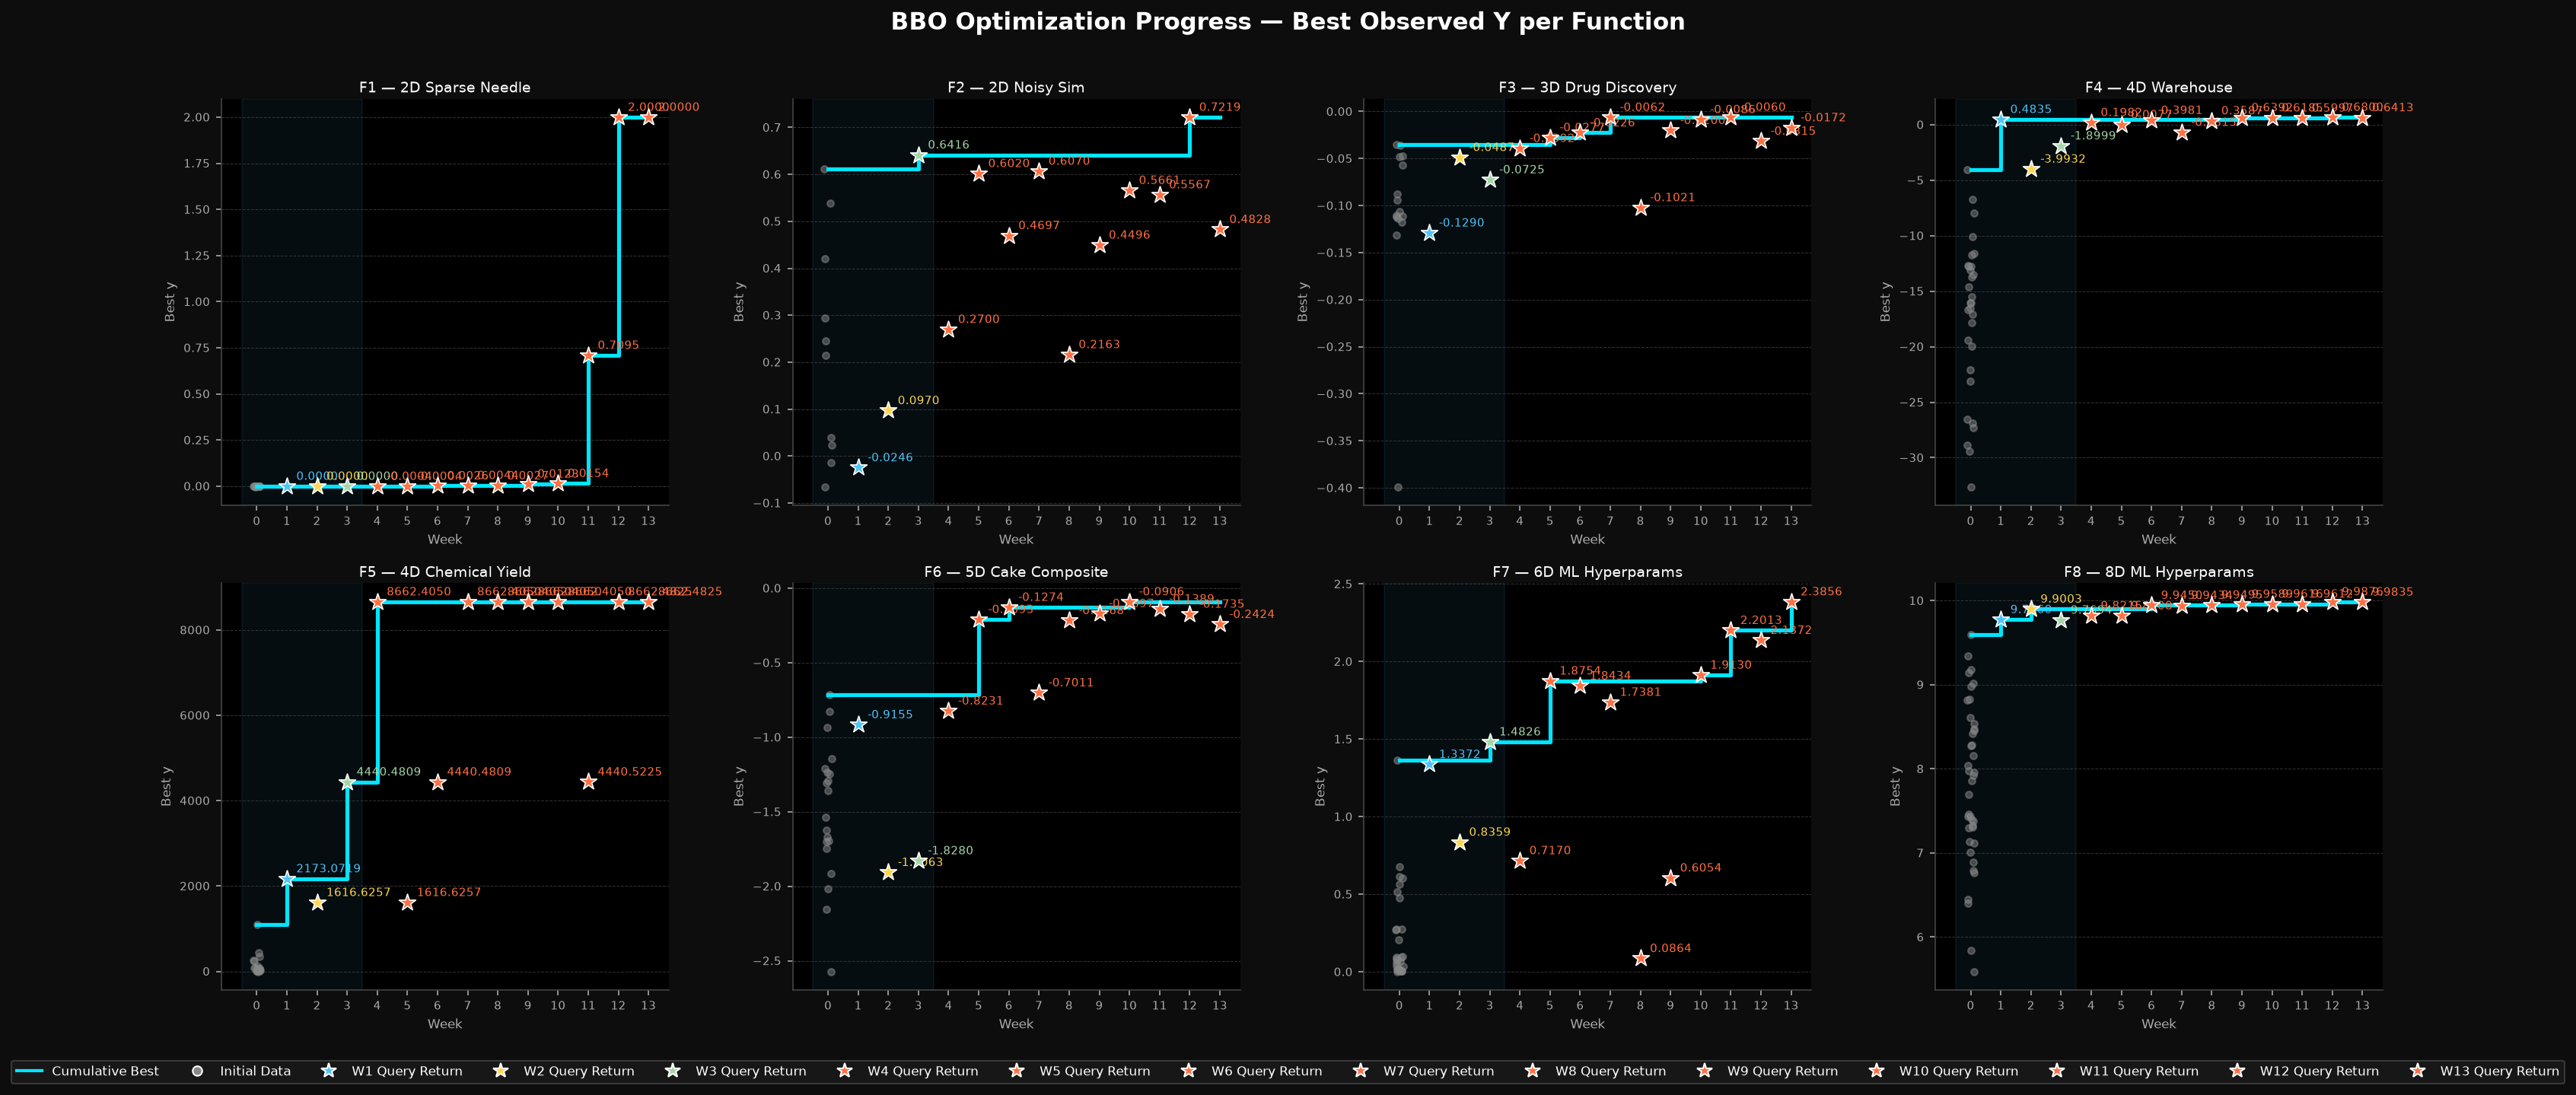

In [4]:
from IPython.display import Image, display

# 1. 13-Week Optimization Trajectory Dashboard
display(Image(filename="results/week_13/progress/trajectory_dashboard_week13.png"))

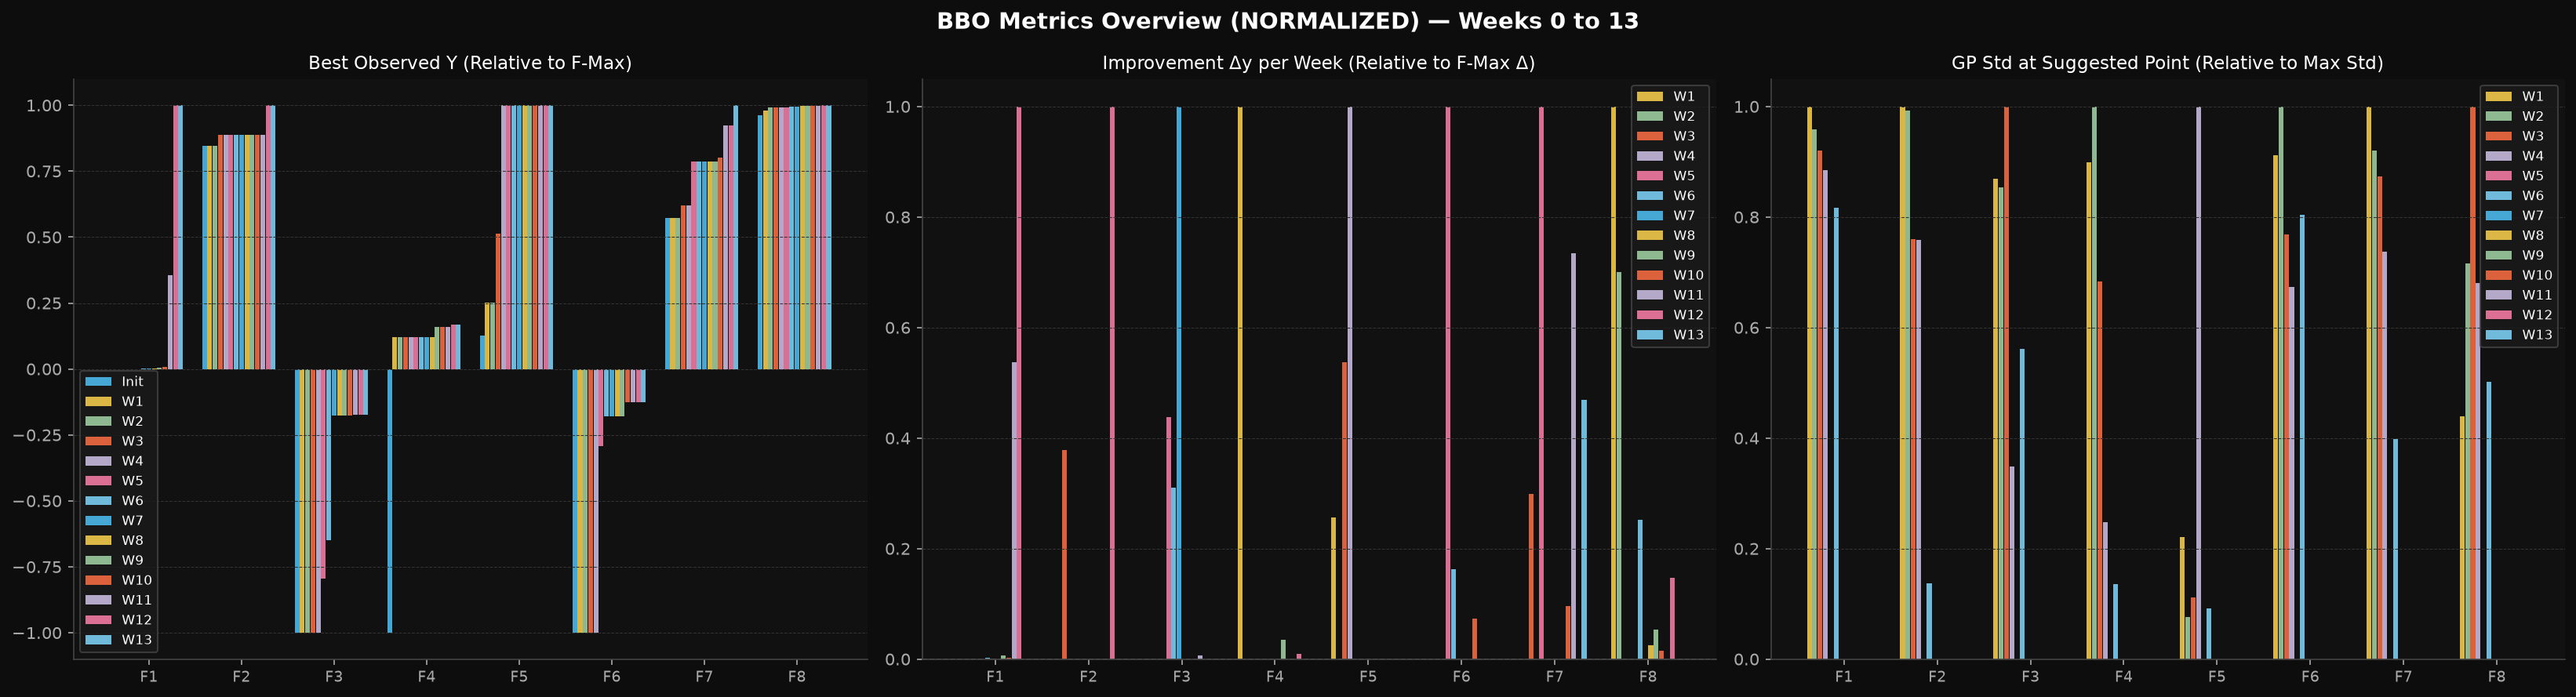

In [5]:
# 2. Normalized GP Exploitation Index & Exploration Ratio (Weeks 1-13)
display(Image(filename="results/week_13/progress/metrics_dashboard_normalized_week13.png"))

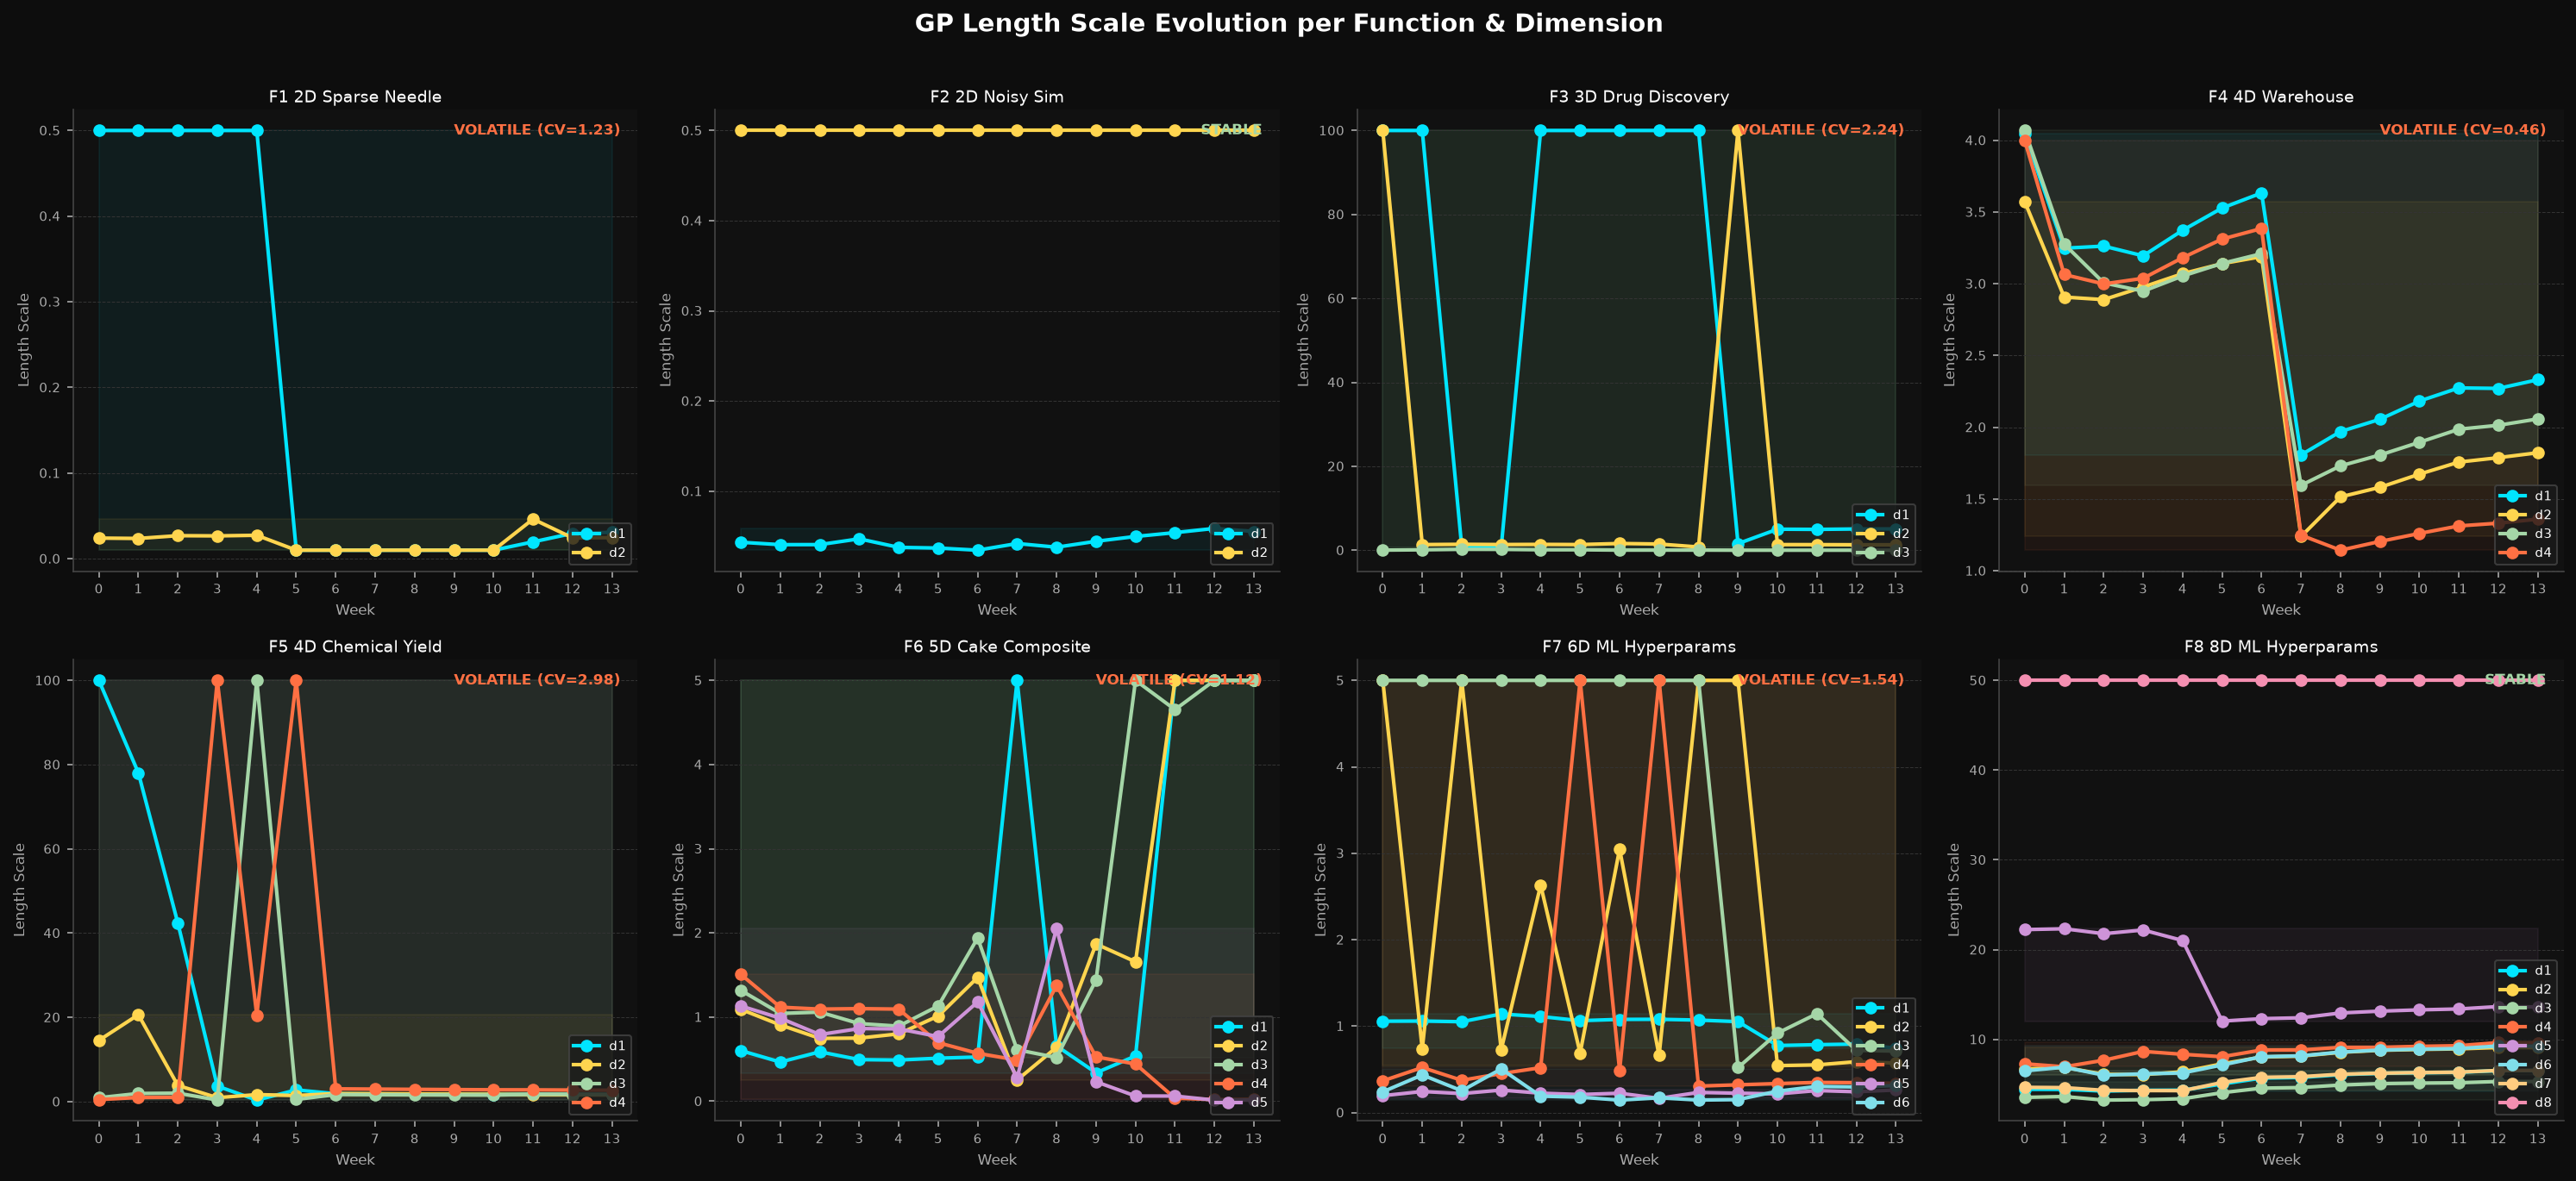

In [6]:
# 3. ARD Kernel Length-Scale Evolution (Weeks 1-13)
display(Image(filename="results/week_13/progress/length_scale_dashboard_week13.png"))